In [ ]:
import sys

print("Python Version:", sys.version)
print("Environment Ready!")

Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Environment Ready!


In [ ]:
import pandas as pd
import zipfile
import io
import urllib.request

# Official UCI dataset URL
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

# Download dataset
response = urllib.request.urlopen(url)

# Extract and load dataset
with zipfile.ZipFile(io.BytesIO(response.read())) as zip_file:
    with zip_file.open("SMSSpamCollection") as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "text"]
        )

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset downloaded successfully!
Dataset shape: (5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
# Check dataset information
print("Dataset Information:")
print(df.info())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate messages
print("\nDuplicate Messages:")
print(df.duplicated().sum())

# Count spam and ham messages
print("\nLabel Distribution:")
print(df["label"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   text    5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

Missing Values:
label    0
text     0
dtype: int64

Duplicate Messages:
403

Label Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


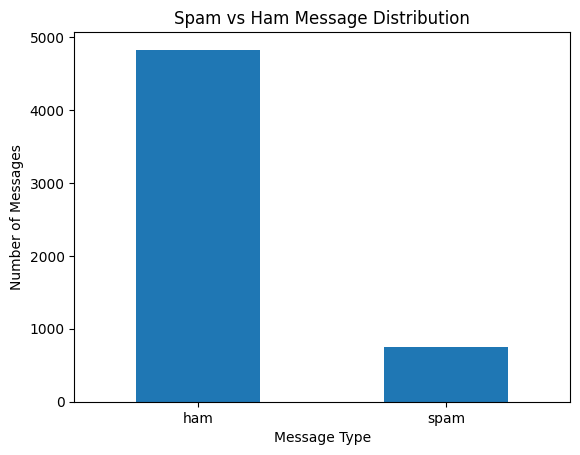

In [ ]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(
    kind="bar",
    title="Spam vs Ham Message Distribution"
)

plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Remove duplicate messages
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

print("After removing duplicates:")
print("Dataset shape:", df.shape)

print("\nLabel distribution:")
print(df["label"].value_counts())

After removing duplicates:
Dataset shape: (5169, 2)

Label distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


In [ ]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df["clean_text"] = df["text"].apply(clean_text)

display(df[["text", "clean_text"]].head(10))

,text,clean_text
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling its been 3 weeks now...
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...
8,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...
9,Had your mobile 11 months or more? U R entitle...,had your mobile 11 months or more u r entitled...


In [ ]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Convert labels into numbers
df["label_encoded"] = df["label"].map({"ham": 0, "spam": 1})

# Separate training and testing data
X_text_train, X_text_test, y_train, y_test = train_test_split(
    df["clean_text"],
    df["label_encoded"].values,
    test_size=0.2,
    random_state=42,
    stratify=df["label_encoded"]
)

# Convert text into numbers
tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(X_text_train)

X_train_seq = tokenizer.texts_to_sequences(X_text_train)
X_test_seq = tokenizer.texts_to_sequences(X_text_test)

# Make all messages equal length
X_train = pad_sequences(
    X_train_seq, maxlen=100, padding="post"
)

X_test = pad_sequences(
    X_test_seq, maxlen=100, padding="post"
)

print("Vocabulary Size:", len(tokenizer.word_index))
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)
print("Training Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)

print("\nOriginal Message:")
print(X_text_train.iloc[0])

print("\nConverted Numbers:")
print(X_train[0])

Vocabulary Size: 8387
Training Shape: (4135, 100)
Testing Shape: (1034, 100)
Training Labels Shape: (4135,)
Testing Labels Shape: (1034,)

Original Message:
tadaaaaa i am home babe are you still up

Converted Numbers:
[3367    2   64   79  149   22    4   82   42    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0]


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    GlobalAveragePooling1D,
    Dense,
    Dropout,
    BatchNormalization
)

model = Sequential([
    Input(shape=(100,)),

    Embedding(
        input_dim=len(tokenizer.word_index) + 1,
        output_dim=32
    ),

    GlobalAveragePooling1D(),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(32, activation="relu"),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 32)        │       268,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 272,897 (1.04 MB)

 Trainable params: 272,769 (1.04 MB)

 Non-trainable params: 128 (512.00 B)

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    GlobalAveragePooling1D,
    Dense,
    Dropout,
    BatchNormalization
)

model = Sequential([
    Embedding(
        input_dim=len(tokenizer.word_index) + 1,
        output_dim=32,
        input_length=100
    ),

    GlobalAveragePooling1D(),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(32, activation="relu"),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Handle imbalanced dataset
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

# Early stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    class_weight=class_weights
)

Epoch 1/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 4.5083e-04 - val_accuracy: 0.9577 - val_loss: 0.2548
Epoch 2/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9988 - loss: 0.0039 - val_accuracy: 0.9782 - val_loss: 0.2152
Epoch 3/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9997 - loss: 0.0026 - val_accuracy: 0.9287 - val_loss: 0.4408
Epoch 4/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9991 - loss: 7.3390e-04 - val_accuracy: 0.9045 - val_loss: 0.5223
Epoch 5/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 6.0341e-04 - val_accuracy: 0.9528 - val_loss: 0.3015


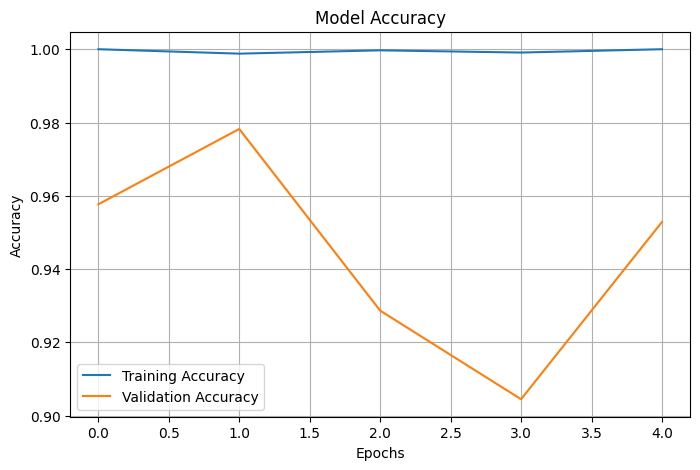

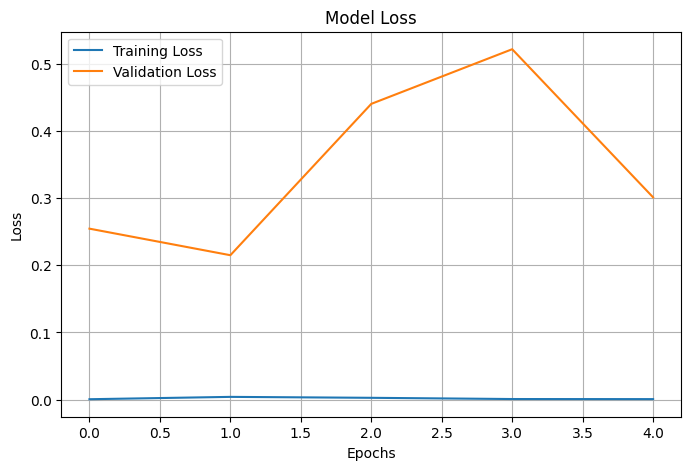

In [ ]:
import matplotlib.pyplot as plt

# Accuracy Graph
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Loss Graph
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Evaluate model
test_loss, test_accuracy = model.evaluate(X_test, y_test)

# Predict test messages
y_prob = model.predict(X_test)
y_pred = (y_prob >= 0.5).astype(int).flatten()

# Calculate performance metrics
print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9749 - loss: 0.2290     
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Test Accuracy: 0.9748549323017408
Precision: 0.9565217391304348
Recall: 0.8396946564885496
F1 Score: 0.8943089430894309

Confusion Matrix:
[[898   5]
 [ 21 110]]

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       903
        Spam       0.96      0.84      0.89       131

    accuracy                           0.97      1034
   macro avg       0.97      0.92      0.94      1034
weighted avg       0.97      0.97      0.97      1034



In [ ]:
def predict_sms(message):

    cleaned = clean_text(message)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding="post"
    )

    probability = float(
        model.predict(padded, verbose=0)[0][0]
    )

    if probability >= 0.5:
        prediction = "SPAM"
        confidence = probability * 100
    else:
        prediction = "HAM"
        confidence = (1 - probability) * 100

    print("Message:", message)
    print("Prediction:", prediction)
    print("Confidence:", f"{confidence:.2f}%")
    print("-" * 40)


# Test new SMS messages
predict_sms("Congratulations! You won a free prize. Claim now!")
predict_sms("Hey, are you coming to college tomorrow?")
predict_sms("URGENT! You have won a cash reward. Call now!")

Message: Congratulations! You won a free prize. Claim now!
Prediction: HAM
Confidence: 99.97%
----------------------------------------
Message: Hey, are you coming to college tomorrow?
Prediction: HAM
Confidence: 100.00%
----------------------------------------
Message: URGENT! You have won a cash reward. Call now!
Prediction: HAM
Confidence: 99.94%
----------------------------------------


In [ ]:
test_messages = [
    "Congratulations! You won a free prize. Claim now!",
    "Hey, are you coming to college tomorrow?",
    "URGENT! You have won a cash reward. Call now!"
]

for message in test_messages:

    cleaned = clean_text(message)
    words = cleaned.split()

    print("\nOriginal:", message)
    print("Cleaned:", cleaned)

    print("\nWord mapping:")

    for word in words:
        print(word, ":", tokenizer.word_index.get(word, "OOV"))

    sequence = tokenizer.texts_to_sequences([cleaned])

    print("\nSequence:", sequence)


Original: Congratulations! You won a free prize. Claim now!
Cleaned: congratulations you won a free prize claim now

Word mapping:
congratulations : 810
you : 4
won : 196
a : 6
free : 56
prize : 151
claim : 134
now : 24

Sequence: [[810, 4, 196, 6, 56, 151, 134, 24]]

Original: Hey, are you coming to college tomorrow?
Cleaned: hey are you coming to college tomorrow

Word mapping:
hey : 117
are : 22
you : 4
coming : 223
to : 3
college : 825
tomorrow : 137

Sequence: [[117, 22, 4, 223, 3, 825, 137]]

Original: URGENT! You have won a cash reward. Call now!
Cleaned: urgent you have won a cash reward call now

Word mapping:
urgent : 209
you : 4
have : 17
won : 196
a : 6
cash : 182
reward : 906
call : 21
now : 24

Sequence: [[209, 4, 17, 196, 6, 182, 906, 21, 24]]


In [ ]:
import pandas as pd

# Get spam probabilities for test messages
spam_probabilities = model.predict(
    X_test, verbose=0
).flatten()

# Create results table
test_results = pd.DataFrame({
    "Message": X_text_test.values,
    "Actual_Label": y_test,
    "Spam_Probability": spam_probabilities
})

# Display 10 actual spam messages
actual_spam = test_results[
    test_results["Actual_Label"] == 1
].sort_values(
    by="Spam_Probability",
    ascending=True
)

display(actual_spam.head(10))

,Message,Actual_Label,Spam_Probability
801,would you like to see my xxx pics they are so ...,1,4.480014e-11
826,ringtoneking 84484,1,1.734836e-08
486,in the simpsons movie released in july 2007 na...,1,2.417583e-08
437,babe u want me dont u baby im nasty and have a...,1,2.459644e-08
308,hi its lucy hubby at meetins all day fri i wil...,1,8.276371e-07
326,missed call alert these numbers called but lef...,1,1.830277e-06
726,want explicit sex in 30 secs ring 02073162414 ...,1,3.762719e-06
456,check out choose your babe videos smsshsexnetu...,1,4.281964e-06
690,latest news police station toilet stolen cops ...,1,2.981841e-05
803,100 dating service call 09064012103 box334sk38ch,1,6.024789e-05


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    Bidirectional,
    LSTM,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping

improved_model = Sequential([
    Input(shape=(100,)),

    Embedding(
        input_dim=len(tokenizer.word_index) + 1,
        output_dim=32
    ),

    Bidirectional(LSTM(32)),

    Dense(32, activation="relu"),
    BatchNormalization(),
    Dropout(0.4),

    Dense(1, activation="sigmoid")
])

improved_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

improved_history = improved_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    class_weight=class_weights
)

improved_model.summary()

Epoch 1/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - accuracy: 0.7969 - loss: 0.3361 - val_accuracy: 0.8791 - val_loss: 0.3384
Epoch 2/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - accuracy: 0.9661 - loss: 0.1105 - val_accuracy: 0.9746 - val_loss: 0.2828
Epoch 3/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.9909 - loss: 0.0477 - val_accuracy: 0.9855 - val_loss: 0.0862
Epoch 4/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9955 - loss: 0.0284 - val_accuracy: 0.9903 - val_loss: 0.0688
Epoch 5/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.9958 - loss: 0.0164 - val_accuracy: 0.9722 - val_loss: 0.0999
Epoch 6/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.9994 - loss: 0.0085 - val_accuracy: 0.9855 - val_loss: 0.0668
Epoch 7/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.9985 - loss: 0.0103 - val_accuracy: 0.9674 - val_loss: 0.1197
Epoch 8/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9927 - loss: 0.0186 - val_accu

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 100, 32)        │       268,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 861,765 (3.29 MB)

 Trainable params: 287,233 (1.10 MB)

 Non-trainable params: 64 (256.00 B)

 Optimizer params: 574,468 (2.19 MB)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Old model predictions
old_prob = model.predict(X_test, verbose=0).flatten()
old_pred = (old_prob >= 0.5).astype(int)

# Improved model predictions
new_prob = improved_model.predict(X_test, verbose=0).flatten()
new_pred = (new_prob >= 0.5).astype(int)

# Compare both models
comparison = pd.DataFrame([
    {
        "Model": "Old Neural Network",
        "Accuracy": accuracy_score(y_test, old_pred),
        "Precision": precision_score(y_test, old_pred),
        "Recall": recall_score(y_test, old_pred),
        "F1 Score": f1_score(y_test, old_pred)
    },
    {
        "Model": "Improved Bidirectional LSTM",
        "Accuracy": accuracy_score(y_test, new_pred),
        "Precision": precision_score(y_test, new_pred),
        "Recall": recall_score(y_test, new_pred),
        "F1 Score": f1_score(y_test, new_pred)
    }
])

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Old Neural Network,0.9749,0.9565,0.8397,0.8943
1,Improved Bidirectional LSTM,0.9855,0.9603,0.9237,0.9416


In [ ]:
def predict_sms(message):

    cleaned = clean_text(message)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding="post"
    )

    probability = float(
        improved_model.predict(padded, verbose=0)[0][0]
    )

    if probability >= 0.5:
        prediction = "SPAM"
        confidence = probability * 100
    else:
        prediction = "HAM"
        confidence = (1 - probability) * 100

    print("Message:", message)
    print("Prediction:", prediction)
    print("Confidence:", f"{confidence:.2f}%")
    print("-" * 40)


predict_sms("Congratulations! You won a free prize. Claim now!")

predict_sms("Hey, are you coming to college tomorrow?")

predict_sms("URGENT! You have won a cash reward. Call now!")

Message: Congratulations! You won a free prize. Claim now!
Prediction: SPAM
Confidence: 99.96%
----------------------------------------
Message: Hey, are you coming to college tomorrow?
Prediction: HAM
Confidence: 99.56%
----------------------------------------
Message: URGENT! You have won a cash reward. Call now!
Prediction: SPAM
Confidence: 99.92%
----------------------------------------


Confusion Matrix:
[[898   5]
 [ 10 121]]

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       903
        Spam       0.96      0.92      0.94       131

    accuracy                           0.99      1034
   macro avg       0.97      0.96      0.97      1034
weighted avg       0.99      0.99      0.99      1034



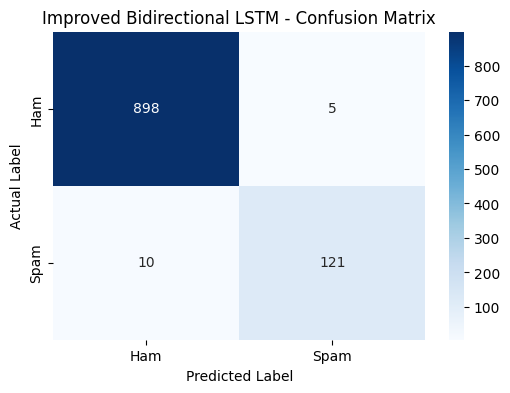

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Improved model predictions
y_pred_final = (
    improved_model.predict(X_test, verbose=0) >= 0.5
).astype(int).flatten()

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_final)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_final,
    target_names=["Ham", "Spam"]
))

# Visualize confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Improved Bidirectional LSTM - Confusion Matrix")
plt.show()